# EDA 1 · Data: collection, cleaning, review slices

1. **Collection**: how much data per game, language and time.
2. **Cleaning**: what each rule removes.
3. **Review slices**: 👍/👎 by genre, text length, playtime, helpfulness, early access / Deck / free copies.


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

from src.config import CONFIG, game_names
from src.db import read
from src.viz.charts import LANG_COLORS, SERIES_COLOR, use_style

pd.set_option("display.max_colwidth", 120)
use_style()
LANGS = CONFIG.reviews.languages

In [2]:
games = pd.Series(game_names())
# millions of reviews: only the columns used below, text length instead of the texts
reviews = read.reviews(
    columns=["recommendation_id", "appid", "language", "created_at", "updated_at", "voted_up", "votes_up",
             "author_playtime_at_review", "received_for_free", "steam_purchase",
             "written_during_early_access", "primarily_steam_deck"],
    flag_columns=["text_language", "is_edited", "keep"],
    text_length=True,
)
reviews["game"] = reviews["appid"].map(games)
pd.Series({"games": len(games), "reviews": len(reviews)})

games            62
reviews    26654373
dtype: int64

## 1. Collection

### 1.1 Reviews per game × language, and coverage against Steam's totals


In [3]:
ours = reviews.groupby(["game", "appid", "language"]).agg(
    collected=("recommendation_id", "size"),
    first_review=("created_at", "min"),
    last_review=("created_at", "max"),
    share_positive=("voted_up", "mean"),
)
steam_total = (
    read.review_totals()
    .sort_values("fetched_at")
    .groupby(["appid", "language"])["total_reviews"]
    .last()
    .rename("steam_total")
)
coverage = ours.join(steam_total, on=["appid", "language"])
coverage["coverage"] = coverage["collected"] / coverage["steam_total"]
coverage.round({"share_positive": 3, "coverage": 3})

collected              first_review  \
game               appid   language                                        
ARC Raiders        1808500 english      259756 2025-10-30 09:39:34+00:00   
                           italian           1 2025-11-25 16:45:52+00:00   
                           russian       50275 2025-10-30 09:40:54+00:00   
                           schinese       5862 2025-10-30 09:41:26+00:00   
                           tchinese       1628 2025-10-30 10:30:13+00:00   
...                                        ...                       ...   
XCOM® 2            268500  tchinese       1203 2016-02-04 19:44:11+00:00   
shapez 2 - Factory 2162800 english        9707 2024-08-15 11:01:56+00:00   
                           russian         690 2024-08-15 12:13:03+00:00   
                           schinese       1779 2024-08-15 11:07:13+00:00   
                           tchinese        213 2024-08-15 11:56:33+00:00   

                                                  last_review  share_positive  \
game               appid   language                                             
ARC Raiders        1808500 english  2026-11-07 06:13:27+00:00           0.811   
                           italian  2025-11-25 16:45:52+00:00           1.000   
                           russian  2026-11-07 06:50:26+00:00           0.787   
                           schinese 2026-11-06 20:36:07+00:00           0.674   
                           tchinese 2026-11-07 06:51:29+00:00           0.649   
...                                                       ...             ...   
XCOM® 2            268500  tchinese 2026-10-26 06:12:32+00:00           0.851   
shapez 2 - Factory 2162800 english  2026-11-08 21:04:09+00:00           0.970   
                           russian  2026-11-02 09:35:49+00:00           0.961   
                           schinese 2026-11-08 20:39:43+00:00           0.953   
                           tchinese 2026-11-03 06:35:44+00:00           0.962   

                                     steam_total  coverage  
game               appid   language                         
ARC Raiders        1808500 english      259822.0     1.000  
                           italian           NaN       NaN  
                           russian       50306.0     0.999  
                           schinese       5864.0     1.000  
                           tchinese       1627.0     1.001  
...                                          ...       ...  
XCOM® 2            268500  tchinese       1203.0     1.000  
shapez 2 - Factory 2162800 english        9707.0     1.000  
                           russian         690.0     1.000  
                           schinese       1779.0     1.000  
                           tchinese        213.0     1.000  

[317 rows x 6 columns]

In [4]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(coverage)

collected  \
game                             appid   language                
ARC Raiders                      1808500 english        259756   
                                         italian             1   
                                         russian         50275   
                                         schinese         5862   
                                         tchinese         1628   
Apex Legends™                    1172470 czech               1   
                                         english        453103   
                                         japanese            2   
                                         latam               1   
                                         romanian            1   
                                         russian        114700   
                                         schinese       273060   
                                         tchinese        35501   
Balatro                          2379780 english        124179   
                                         russian          6148   
                                         schinese        29083   
                                         tchinese         1378   
Baldur's Gate 3                  1086940 brazilian           1   
                                         english        507545   
                                         russian         67458   
                                         schinese       102375   
                                         tchinese         7394   
Battlefield™ 1                   1238840 english         54172   
                                         russian         16010   
                                         schinese        88054   
                                         tchinese         1941   
Borderlands 4                    1285190 english         61119   
                                         russian          2427   
                                         schinese         8490   
                                         tchinese          371   
Brawlhalla                       291550  english        180055   
                                         latam               1   
                                         russian         31898   
                                         schinese         7137   
                                         tchinese         1619   
Call of Duty®: Modern Warfare® 4 4435490 english          6378   
                                         russian          1435   
                                         schinese         2242   
                                         tchinese          154   
Call of Duty®: Warzone™          1962663 english         21665   
                                         russian          6755   
                                         schinese         4930   
                                         tchinese          257   
Clair Obscur: Expedition 33      1903340 brazilian           1   
                                         english        141371   
                                         russian         17303   
                                         schinese        39800   
                                         tchinese         4725   
Counter-Strike 2                 730     brazilian           1   
                                         czech               1   
                                         danish              2   
                                         english       2643274   
                                         french              1   
                                         greek               1   
                                         japanese            2   
                                         koreana             1   
                                         latam               2   
                                         norwegian           1   
                                         polish              1   
                           

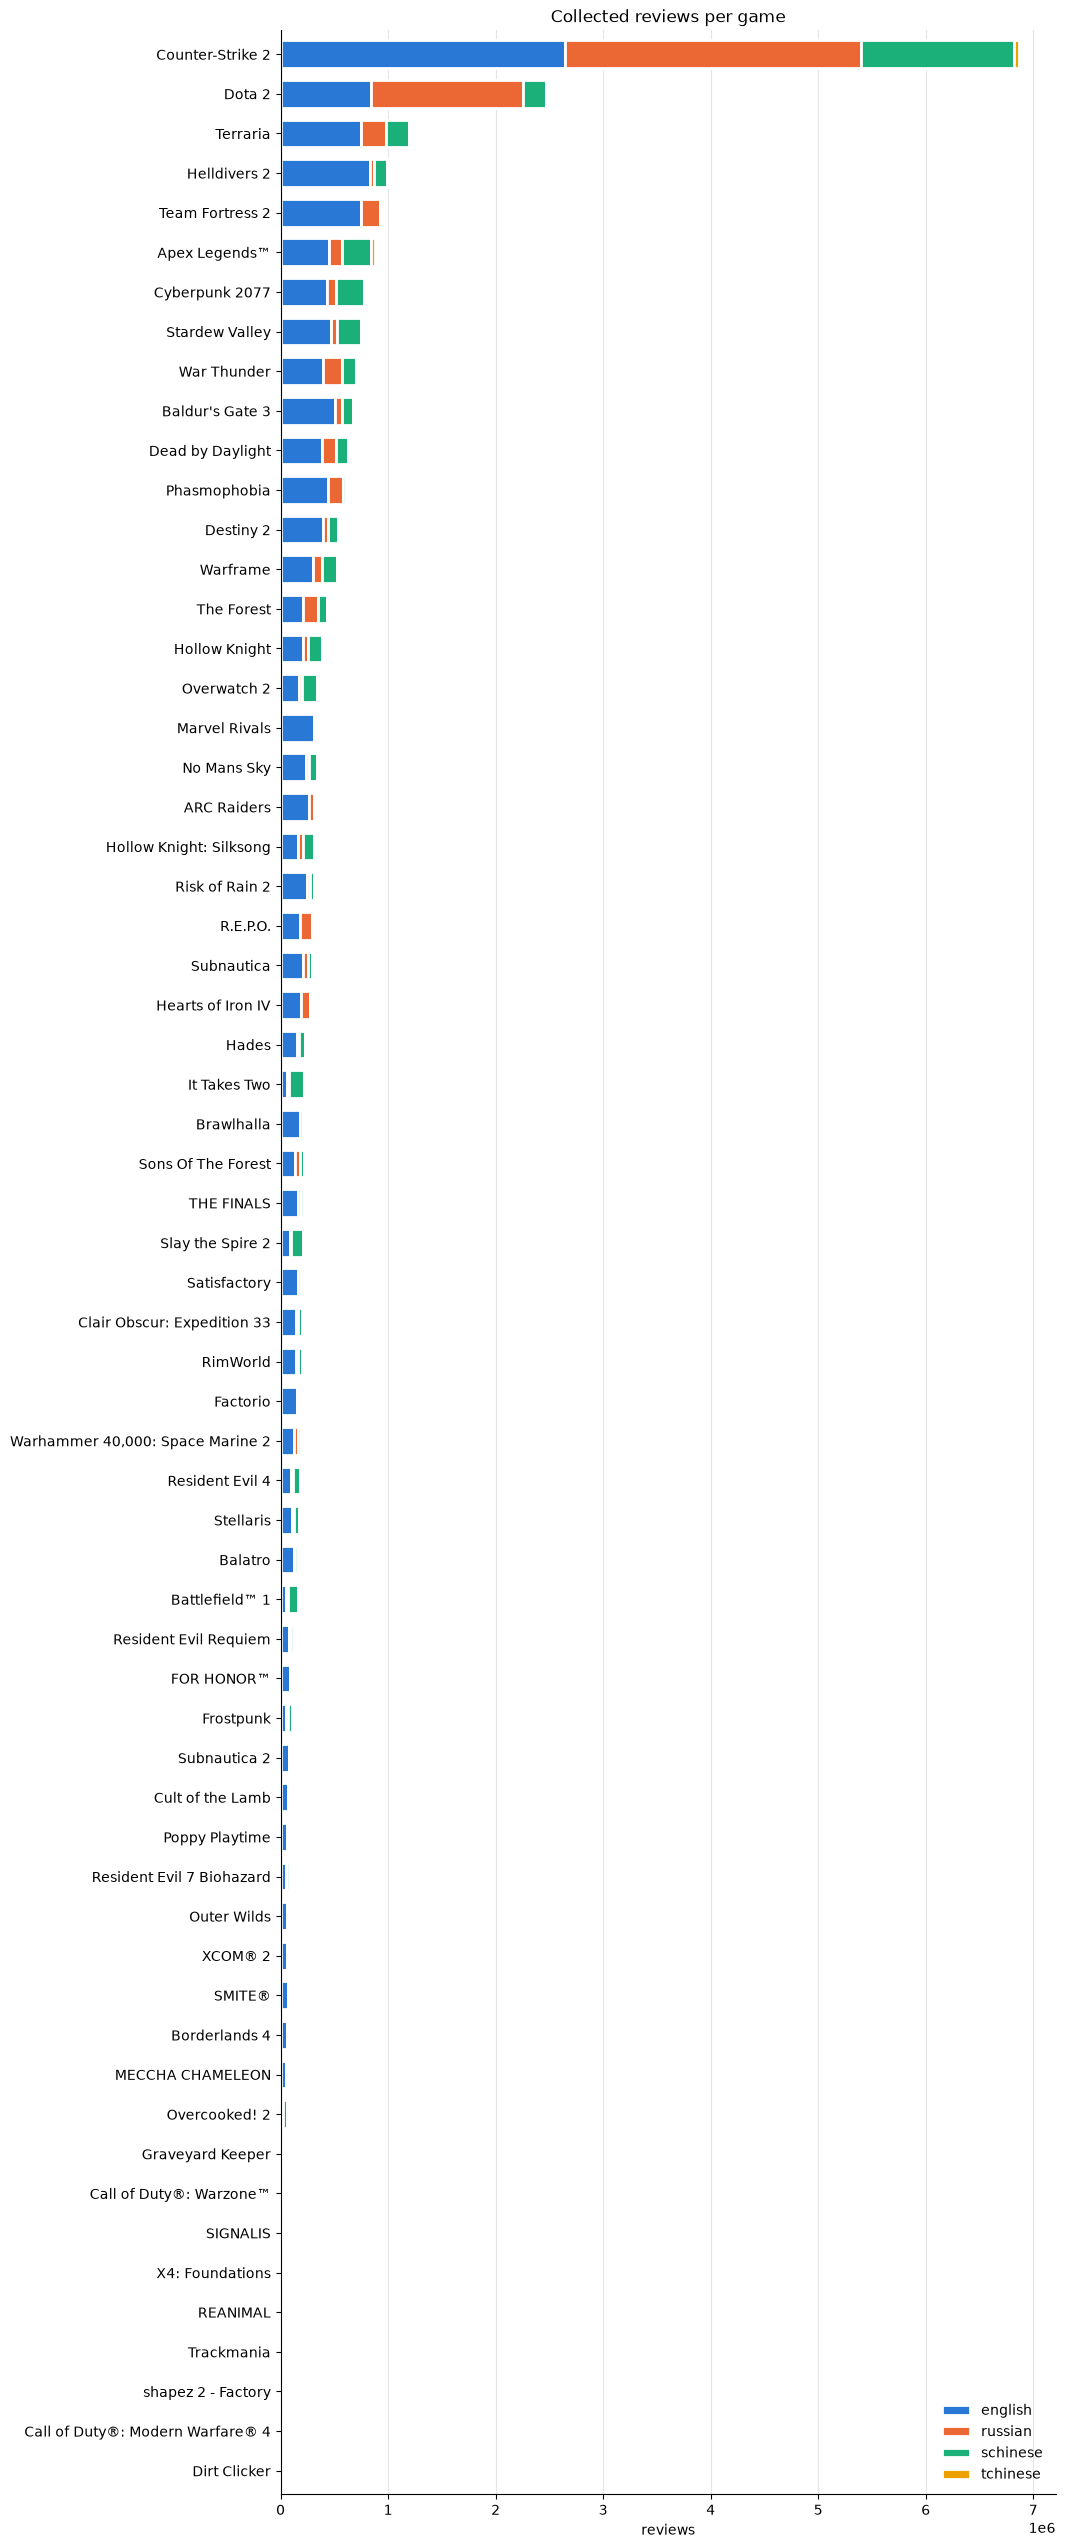

In [5]:
per_game = reviews.groupby(["game", "language"]).size().unstack(fill_value=0)
per_game = per_game[[c for c in CONFIG.reviews.languages if c in per_game]]  # drop odd labels
per_game = per_game.loc[per_game.sum(axis=1).sort_values().index]

ax = per_game.plot.barh(
    stacked=True, color=[LANG_COLORS.get(c, "#888888") for c in per_game.columns],
    edgecolor="white", linewidth=2, width=0.7, figsize=(10, 0.5 * len(per_game) + 1),
)
ax.set(title="Collected reviews per game", xlabel="reviews", ylabel="")
ax.set_axisbelow(True)
ax.grid(axis="y", visible=False)
ax.legend(title="", frameon=False, loc="lower right");

### 1.2 Volume over time

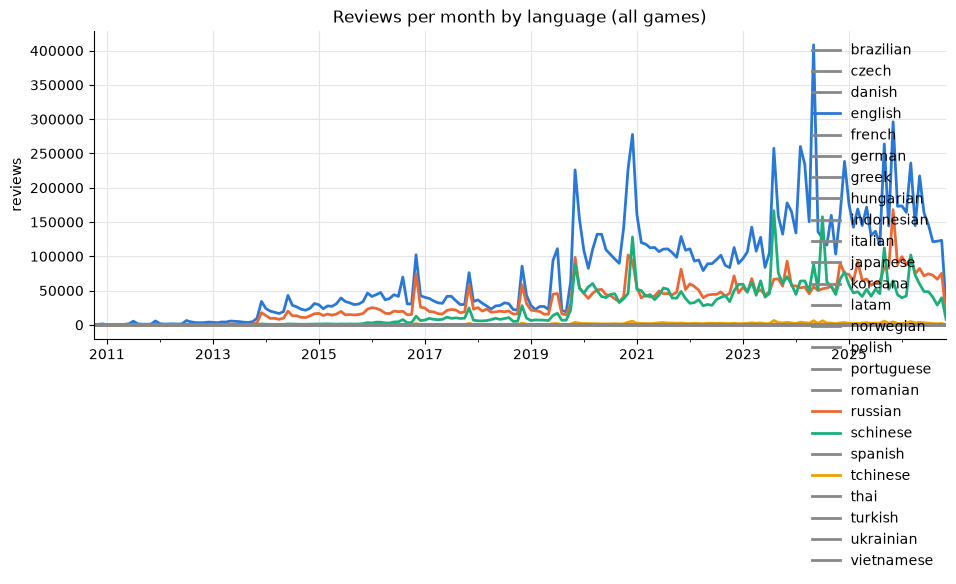

In [6]:
month = reviews["created_at"].dt.tz_convert(None).dt.to_period("M").dt.to_timestamp()
monthly = reviews.groupby([month, "language"]).size().unstack(fill_value=0)

ax = monthly.plot(color=[LANG_COLORS.get(c, "#888888") for c in monthly.columns])
ax.set(title="Reviews per month by language (all games)", xlabel="", ylabel="reviews")
ax.legend(title="", frameon=False);

### 1.3 Text length and author fields

In [7]:
reviews.groupby("language")["text_len"].describe(percentiles=[0.1, 0.5, 0.9]).round(0)

,count,mean,std,min,10%,50%,90%,max
language,,,,,,,,
brazilian,4.0,82.0,68.0,8.0,26.0,73.0,145.0,173.0
czech,6.0,48.0,50.0,14.0,15.0,27.0,101.0,144.0
danish,2.0,17.0,18.0,4.0,7.0,17.0,27.0,30.0
english,14800429.0,148.0,1258.0,0.0,4.0,34.0,328.0,4539599.0
french,3.0,189.0,175.0,13.0,49.0,192.0,329.0,363.0
german,2.0,18.0,19.0,4.0,7.0,18.0,28.0,31.0
greek,1.0,657.0,NaN,657.0,657.0,657.0,657.0,657.0
hungarian,1.0,25.0,NaN,25.0,25.0,25.0,25.0,25.0
indonesian,6.0,157.0,219.0,14.0,18.0,91.0,364.0,595.0


In [8]:
reviews.groupby("language").agg(
    median_hours_at_review=("author_playtime_at_review", lambda s: s.median() / 60),
    share_free=("received_for_free", "mean"),
    share_steam_purchase=("steam_purchase", "mean"),
).round(3)

,median_hours_at_review,share_free,share_steam_purchase
language,,,
brazilian,38.950,0.000,1.000
czech,372.775,0.000,1.000
danish,250.217,0.000,1.000
english,57.183,0.014,0.900
french,224.633,0.000,1.000
german,848.608,0.000,1.000
greek,137.883,0.000,1.000
hungarian,2.817,0.000,1.000
indonesian,18.525,0.167,0.833


### 1.4 Steam language vs language of the text


In [9]:
pd.crosstab(reviews["language"], reviews["text_language"], normalize="index").round(3)

text_language,de,en,es,fr,ja,ko,pl,pt,ru,tr,uk,zh
language,,,,,,,,,,,,
brazilian,0.000,0.000,0.000,0.0,0.000,0.0,0.000,1.000,0.000,0.000,0.000,0.000
czech,0.000,0.500,0.000,0.0,0.000,0.0,0.000,0.000,0.500,0.000,0.000,0.000
english,0.001,0.993,0.001,0.0,0.000,0.0,0.001,0.001,0.002,0.001,0.000,0.001
french,0.000,0.000,0.000,1.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
german,1.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
greek,0.000,1.000,0.000,0.0,0.000,0.0,0.000,0.000,0.000,0.000,0.000,0.000
indonesian,0.000,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.000,1.000,0.000,0.000
japanese,0.143,0.000,0.000,0.0,0.000,0.0,0.000,0.000,0.429,0.000,0.000,0.429
koreana,0.000,0.000,0.000,0.0,0.000,0.5,0.000,0.000,0.500,0.000,0.000,0.000


## 2. Cleaning

### 2.1 How much each rule removes (latest run)

In [10]:
report = read.cleaning_report()
latest = report[report["run_id"] == report["run_id"].max()]
counts = latest.groupby(["rule", "language"])[["n_flagged", "n_total"]].sum()
(counts["n_flagged"] / counts["n_total"]).unstack("language").style.format("{:.1%}")

language,brazilian,czech,danish,english,french,german,greek,hungarian,indonesian,italian,japanese,koreana,latam,norwegian,polish,portuguese,romanian,russian,schinese,spanish,tchinese,thai,turkish,ukrainian,vietnamese
rule,,,,,,,,,,,,,,,,,,,,,,,,,
dropped,0.0%,0.0%,0.0%,4.3%,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%,15.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,8.7%,8.1%,0.0%,6.6%,25.0%,0.0%,10.0%,0.0%
duplicate_text,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.1%,0.0%,0.1%,0.0%,0.0%,0.0%,0.0%
edited,25.0%,16.7%,0.0%,13.9%,66.7%,50.0%,100.0%,0.0%,16.7%,0.0%,0.0%,0.0%,12.5%,0.0%,0.0%,0.0%,0.0%,16.9%,11.1%,33.3%,15.3%,50.0%,25.0%,30.0%,0.0%
empty,0.0%,0.0%,0.0%,3.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,15.4%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,6.2%,4.3%,0.0%,3.8%,25.0%,0.0%,0.0%,0.0%
junk,0.0%,0.0%,0.0%,2.9%,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%,7.7%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,6.7%,6.3%,0.0%,5.2%,25.0%,0.0%,10.0%,0.0%
lang_mismatch,0.0%,0.0%,0.0%,0.7%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.9%,0.8%,0.0%,3.3%,0.0%,0.0%,0.0%,0.0%
short,25.0%,50.0%,50.0%,37.5%,33.3%,50.0%,0.0%,0.0%,16.7%,100.0%,30.8%,0.0%,37.5%,33.3%,0.0%,0.0%,66.7%,47.5%,33.9%,66.7%,37.5%,50.0%,25.0%,40.0%,50.0%


### 2.2 Examples per rule

Check by eye that each rule catches what it should.

In [11]:
def examples(rule: str, n: int = 8) -> pd.DataFrame:
    return read.flagged_examples(rule, n).assign(
        review=lambda d: d["review"].str.replace(r"\s+", " ", regex=True).str.slice(0, 120)
    )

for rule in ["is_empty", "is_junk", "is_duplicate_text", "is_lang_mismatch"]:
    print(f"\n=== {rule}")
    display(examples(rule))


=== is_empty


,language,lang_detected,lang_conf,review
0,english,None,None,👻👍
1,russian,None,None,
2,schinese,None,None,kt
3,schinese,None,None,12
4,english,None,None,gg
5,english,None,None,:D
6,russian,None,None,s
7,english,None,None,w



=== is_junk


,language,lang_detected,lang_conf,review
0,russian,None,None,.
1,schinese,None,None,6
2,english,None,None,1
3,english,None,None,k
4,schinese,None,None,6666666666666
5,russian,None,None,.
6,english,None,None,;
7,russian,None,None,123



=== is_duplicate_text


,language,lang_detected,lang_conf,review
0,schinese,ja,1.000000,"请给我点数，我想买个背景但是没有钱，虽然不会让你的牛子变长，但是这个世界上会又多一个人为你祝福着 Please give me some points. I want to buy a background, but I have ..."
1,english,en,0.954374,i am training to be an automotive technician in real life. This game is very fun and reallistic!
2,russian,ru,0.991611,"Оладушки на молоке: Продукты (на 6 порций) Мука - 1-1,5 стакана Молоко - 1 стакан Яйцо куриное - 2-3 шт. Сода - 0,25..."
3,russian,ru,1.000000,(Рецепт блинов) 1.молоко 500 мл 2.яйца 3 шт. 3.мука 200 г 4.масло сливочное (или растительное) 30 г (2 ст. ложки) 5....
4,schinese,zh,1.000000,摸一下猫猫会张嘴，一个赞摸一次！！！ ⣿⣿⣿⠟⠛⠛⠻⣿⣿⣿⣿⣿⣿⣿⣿⣿⣿⡟⢋⣩⣉⢻ ⣿⣿⣿⠀⣿⣶⣕⣈⠹⠿⠿⠿⠿⠟⠛⣛⢋⣰⠣⣿⣿⠀⣿ ⣿⣿⣿⡀⣿⣿⣿⣧⢻⣿⣶⣷⣿⣿⣿⣿⣿⣿⠿⠶⡝⠀⣿ ⣿⣿⣿⣷⠘⣿⣿⣿⢏⣿⣿⣋⣀⣈⣻⣿⣿⣷⣤⣤⣿⡐⢿ ⣿⣿...
5,russian,zh,0.000000,᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю ϶ᴛᴏ🖤᧐б᧐жᴀю...
6,russian,ru,1.000000,"Оладьи на кефире Оладьи на кефире, пожалуй, самое лучшее, что хорошая мама может предложить на завтрак своему сонном..."
7,schinese,zh,1.000000,9敏~集美们，这款游戏真的绝绝子，我直接一整个暴风吸入o.O整个就是一大震精状态了家人们，安利安利必须给家人们安利！因为身为小仙女的沵只有自己去玩去体验了才知道什么叫香喷喷 软乎乎 糯叽叽 舒服到翘jiojio!!!



=== is_lang_mismatch


,language,lang_detected,lang_conf,review
0,russian,en,0.967979,"All you need to do in this game is to farm things to farm other things. Well, sometimes it's fun to FARM bosses too"
1,russian,en,0.936743,"Good game, recommended!"
2,english,pt,1.000000,Ingrediente – Clatite americane 400 g faina 500 ml lapte 4 oua 3 lingurite rase praf copt 1/2 lingurita rasa bicarbo...
3,english,ru,1.000000,"Вот и вышла легенда! Жаль что на 4 часа, ждём дополнения, игрушка получилась просто бомба! Разработчики как всегда ч..."
4,english,tr,0.999983,Arkadaşla girince güzel oluyor ama benim arkadaşım salak aq kolsuzu siz siz olun solu girmeyin
5,english,tr,0.999997,ewqwrreweewqjtwreweqewqwwqjqwewtrerewqqwqqqq
6,schinese,en,0.975878,very good.I see it's the best peaceful(not) game what I have played.
7,english,tr,0.999246,oyun iyi ingilizleri vuruyoz daha ne diyem


### 2.3 Edited reviews: which date to use

In [12]:
days_to_edit = (reviews["updated_at"] - reviews["created_at"]).dt.total_seconds() / 86400
pd.DataFrame({
    "share_edited": reviews.groupby("language")["is_edited"].mean(),
    "median_days_to_edit": days_to_edit[reviews["is_edited"].eq(True)].groupby(reviews["language"]).median(),
}).round(3)

,share_edited,median_days_to_edit
language,,
brazilian,0.250,1934.155
czech,0.167,444.094
danish,0.000,NaN
english,0.139,441.906
french,0.667,723.206
german,0.500,2029.084
greek,1.000,534.238
hungarian,0.000,NaN
indonesian,0.167,1399.422


### 2.4 Result

In [13]:
reviews.groupby("language")["keep"].agg(total="size", kept="sum", share_kept="mean").round(3)

,total,kept,share_kept
language,,,
brazilian,4,4,1.000
czech,6,6,1.000
danish,2,2,1.000
english,14800429,14162545,0.957
french,3,3,1.000
german,2,2,1.000
greek,1,1,1.000
hungarian,1,1,1.000
indonesian,6,6,1.000


## 3. Review slices (👍/👎)

All reviews, not only kept ones: a vote counts even when its text is junk or empty.

### 3.1 By Steam genre and category

Share of positive reviews over all reviews of the games that have the genre / category (a game has several).

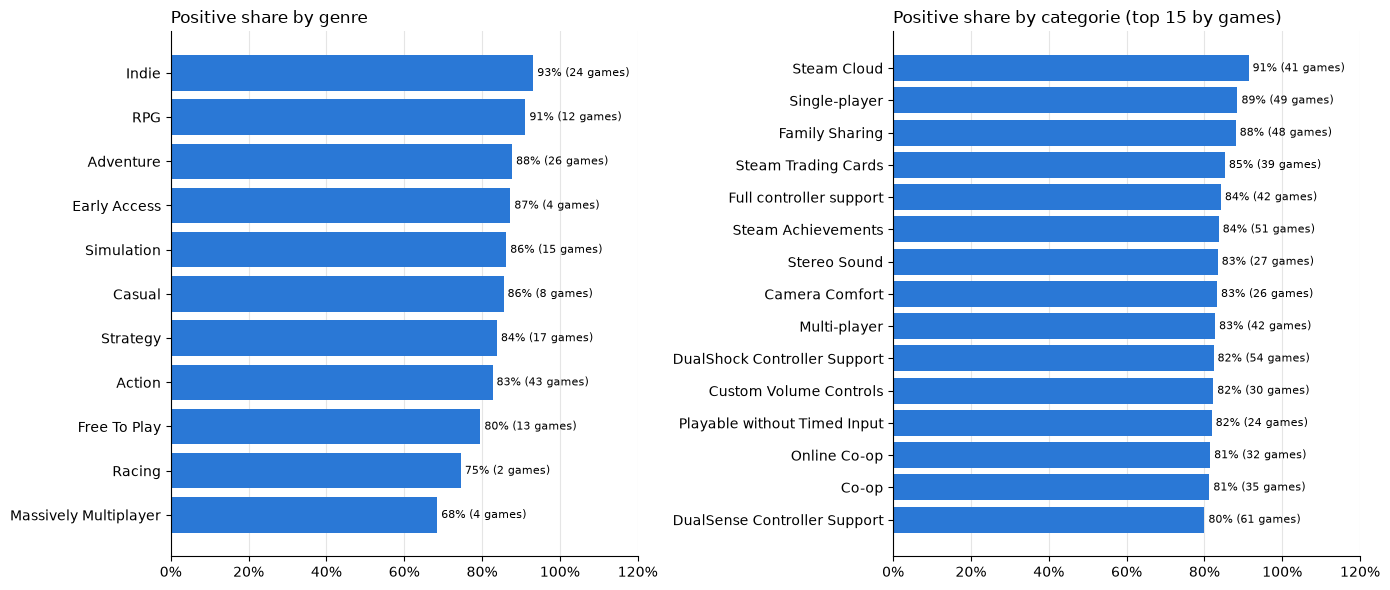

In [14]:
per_game = reviews.groupby("appid")["voted_up"].agg(reviews="size", positive="sum")
tags = read.games().set_index("appid")[["genres", "categories"]].join(per_game, how="inner")


def positive_by_tag(column):
    t = tags.explode(column).groupby(column).agg(games=("reviews", "size"), reviews=("reviews", "sum"),
                                                  positive=("positive", "sum"))
    return t.assign(share=t["positive"] / t["reviews"])


fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, column, top in [(axes[0], "genres", None), (axes[1], "categories", 15)]:
    t = positive_by_tag(column)
    t = (t.nlargest(top, "games") if top else t).sort_values("share")
    ax.barh(t.index, t["share"], color=SERIES_COLOR)
    for y, (share, n) in enumerate(zip(t["share"], t["games"])):
        ax.text(share, y, f" {share:.0%} ({n} games)", va="center", fontsize=8)
    ax.set_xlim(0, 1.2)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(f"Positive share by {column[:-1]}" + (f" (top {top} by games)" if top else ""), loc="left")
    ax.grid(axis="y", visible=False)
fig.tight_layout()

### 3.2 By text length, playtime and helpfulness

One line per Steam language. Bins with few reviews (the long tails) are noisy.

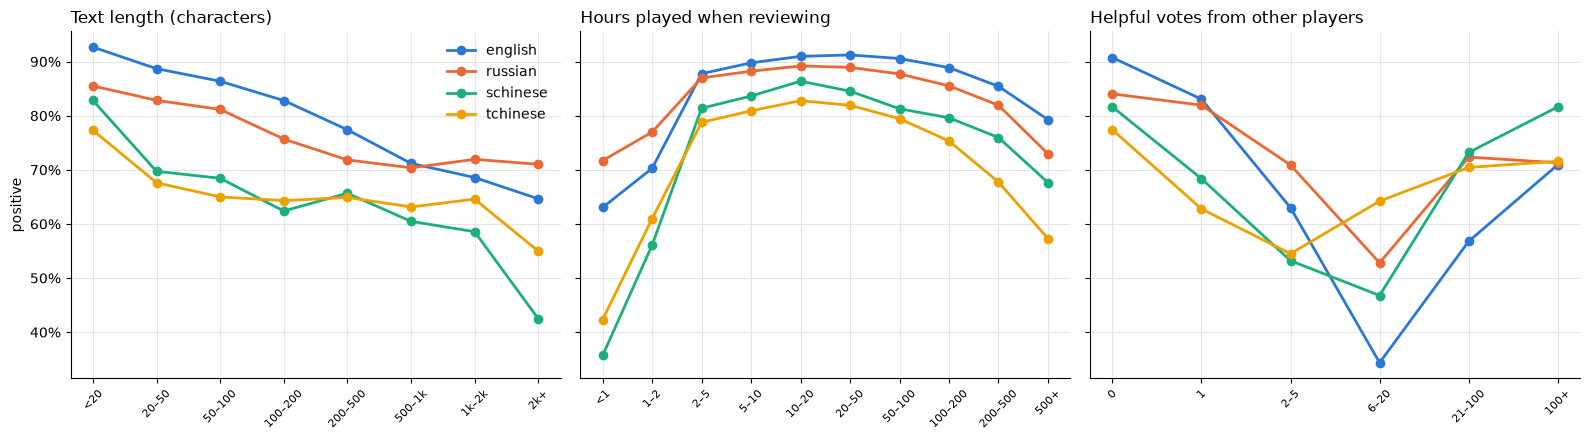

In [15]:
def positive_by_bins(ax, values, edges, labels, title):
    binned = pd.cut(values, bins=edges, labels=labels, right=False)
    for lang in LANGS:
        mine = reviews["language"].eq(lang)
        share = reviews.loc[mine, "voted_up"].groupby(binned[mine], observed=False).mean()
        ax.plot(range(len(labels)), share.to_numpy(), marker="o", color=LANG_COLORS.get(lang), label=lang)
    ax.set_xticks(range(len(labels)), labels, rotation=45, fontsize=8)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_title(title, loc="left")


fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
positive_by_bins(axes[0], reviews["text_len"], [0, 20, 50, 100, 200, 500, 1000, 2000, np.inf],
                 ["<20", "20–50", "50–100", "100–200", "200–500", "500–1k", "1k–2k", "2k+"], "Text length (characters)")
positive_by_bins(axes[1], reviews["author_playtime_at_review"] / 60, [0, 1, 2, 5, 10, 20, 50, 100, 200, 500, np.inf],
                 ["<1", "1–2", "2–5", "5–10", "10–20", "20–50", "50–100", "100–200", "200–500", "500+"],
                 "Hours played when reviewing")
positive_by_bins(axes[2], reviews["votes_up"], [0, 1, 2, 6, 21, 101, np.inf],
                 ["0", "1", "2–5", "6–20", "21–100", "100+"], "Helpful votes from other players")
axes[0].set_ylabel("positive")
axes[0].legend(frameon=False)
fig.tight_layout()

### 3.3 Early access, Steam Deck, free copies

In [16]:
GROUPS = {
    "written_during_early_access": "written in early access",
    "primarily_steam_deck": "played mostly on Steam Deck",
    "received_for_free": "got the game for free",
    "steam_purchase": "bought on Steam",
}
rows = []
for column, name in GROUPS.items():
    yes = reviews[column].eq(True)
    rows.append({"group": name, "reviews": yes.sum(), "share of reviews": yes.mean(),
                 "positive if yes": reviews.loc[yes, "voted_up"].mean(),
                 "positive if no": reviews.loc[~yes, "voted_up"].mean()})
pd.DataFrame(rows).set_index("group").style.format(
    {"reviews": "{:,}", "share of reviews": "{:.1%}", "positive if yes": "{:.0%}", "positive if no": "{:.0%}"}
)

,reviews,share of reviews,positive if yes,positive if no
group,,,,
written in early access,"1,800,298",6.8%,89%,84%
played mostly on Steam Deck,"84,015",0.3%,88%,84%
got the game for free,"326,415",1.2%,87%,84%
bought on Steam,"24,322,320",91.3%,84%,87%
